In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

In [46]:
(x_train, y_train),(x_test, y_test) = keras.datasets.mnist.load_data()

In [13]:
print("shape x train", x_train.shape)
print("shape y train", y_train.shape)
print("shape of x test", x_test.shape)
print("shape of y test", y_test.shape)

shape x train (60000, 28, 28)
shape y train (60000,)
shape of x test (10000, 28, 28)
shape of y test (10000,)


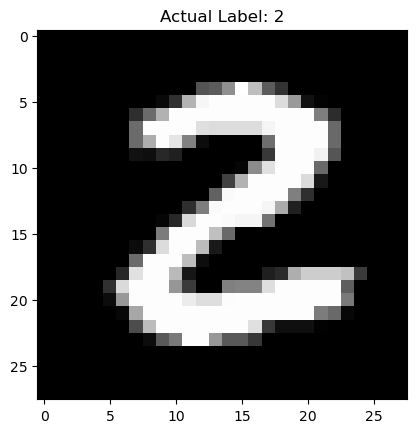

In [36]:
plt.imshow(x_train[25], cmap='gray')
plt.title("Actual Label: " + str(y_train[25]))
plt.show()

In [39]:
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]


In [47]:
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [53]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(50, activation="relu", name="L1"),
    keras.layers.Dense(50, activation="relu", name="L2"),
    keras.layers.Dense(10, activation="softmax", name="output")
])

In [54]:
## compile the model
model.compile(
    optimizer="sgd",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [56]:
## training the neural network

history = model.fit(
    x_train,
    y_train,
    batch_size=30,
    epochs=10,
    validation_data=(x_test, y_test),
    shuffle=True
)

Epoch 1/10


W0000 00:00:1793457461.318017    6598 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8174 - loss: 0.6666 - val_accuracy: 0.9052 - val_loss: 0.3328
Epoch 2/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9118 - loss: 0.3123 - val_accuracy: 0.9215 - val_loss: 0.2736
Epoch 3/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9243 - loss: 0.2638 - val_accuracy: 0.9306 - val_loss: 0.2397
Epoch 4/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9339 - loss: 0.2321 - val_accuracy: 0.9368 - val_loss: 0.2144
Epoch 5/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9401 - loss: 0.2077 - val_accuracy: 0.9424 - val_loss: 0.1947
Epoch 6/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9459 - loss: 0.1881 - val_accuracy: 0.9481 - val_loss: 0.1785
Epoch 7/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9508 - loss: 0.1718 - val_accuracy: 0.9506 - val_loss: 0.1655
Epoch 8/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9550 - loss: 0.1580 - val_accurac

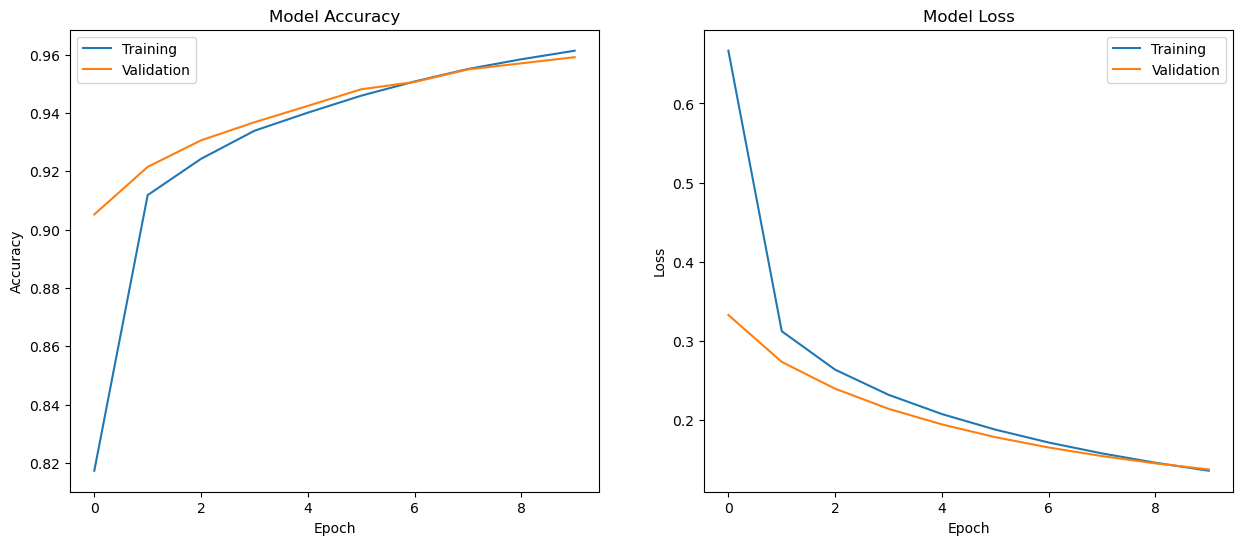

In [59]:
plt.figure(figsize=(15, 6))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training', 'Validation'])

plt.show()

In [60]:
loss, accuracy  = model.evaluate(x_test, y_test)

print(loss, accuracy, accuracy*100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9591 - loss: 0.1378
0.13778427243232727 0.9591000080108643 95.91000080108643


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


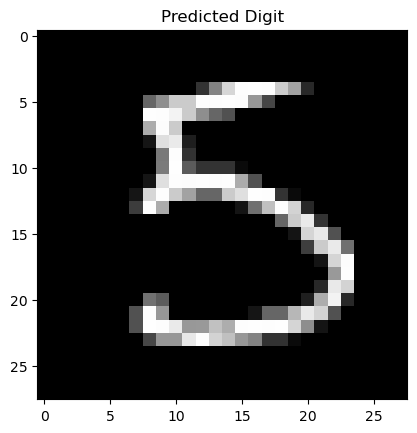

Predicted Value: 5
Actual Value: 5


In [61]:
predicted_value = model.predict(x_test)

plt.imshow(x_test[15], cmap='gray')
plt.title("Predicted Digit")
plt.show()

print("Predicted Value:",
      np.argmax(predicted_value[15]))

print("Actual Value:",
      y_test[15])